In [1]:
# Import cell
!pip install -q transformers scikit-learn
!pip install -q scikit-learn
!pip install -q pandas
!pip install -q numpy
!pip install -q pillow
!pip install -q matplotlib
!pip install -q tqdm
!pip install -q requests

In [2]:
import random
import time
import copy
import gc
import json
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import matplotlib.pyplot as plt


from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from transformers import AutoTokenizer, AutoModel
from datasets import load_dataset, load_from_disk

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score


# make result compatible
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# check for gpu
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

# path folder settings
base = Path("/content/group17")
base.mkdir(exist_ok=True)



Using: cuda


In [3]:
# Folder where the dataset will be saved
dataset_path = base / "dataset"

# Lload dataset if exist
if (dataset_path / "state.json").exists():
  dataset = load_from_disk(str(dataset_path))
  print("Loaded saved dataset")

else:
  # download full data set and save in local memory
  dataset = load_dataset(
      "pranavmr/MM-IMDb",
      split="train"
  )

  # Save locally
  dataset.save_to_disk(str(dataset_path))

print("Total movies:", len(dataset))
print("Columns:", dataset.column_names)

README.md:   0%|          | 0.00/405 [00:00<?, ?B/s]

data/train-00000-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  483MB            

data/train-00000-of-00004.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00001-of-00004.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  482MB            

... (2 outputs left out)

data/train-00003-of-00004.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25959 [00:00<?, ? examples/s]

Saving the dataset (0/4 shards):   0%|          | 0/25959 [00:00<?, ? examples/s]

Total movies: 25959
Columns: ['image', 'text', 'labels']


In [4]:
# save processed movie information
movie_file = base / "movies.pkl"

if movie_file.exists():
  df = pd.read_pickle(movie_file)
else:
  movies = []

  # check every movies in dataset
  for i in tqdm(range(len(dataset))):
    try:
      row = dataset[i]

      plot = row["text"]
      genres = row["labels"]
      poster = row["image"]

      # skip record w
      if not isinstance(plot, str) or not plot.strip():
          continue

      if not genres or poster is None:
          continue

      # check that poster is readable
      poster.load()

      movies.append({
          "id": i,
          "plot": plot.strip(),
          "genres": genres
      })

    except Exception:
        continue

  df = pd.DataFrame(movies)

  # normalise text
  df["plot_key"] = (
      df["plot"]
      .str.lower()
      .str.split()
      .str.join(" ")
  )

  df.to_pickle(movie_file)


print("Original records:", len(dataset))
print("Valid movies:", len(df))
print("Invalid records:", len(dataset) - len(df))

print("Duplicate plots:", df["plot_key"].duplicated().sum())

print(
  "Average plot words:",
  round(df["plot"].str.split().str.len().mean(), 2)
)

print(
  "Average genres per movie:",
  round(df["genres"].apply(len).mean(), 2)
)

display(df.head())

  0%|          | 0/25959 [00:00<?, ?it/s]

Original records: 25959
Valid movies: 25959
Invalid records: 0
Duplicate plots: 14
Average plot words: 106.23
Average genres per movie: 2.48


,id,plot,genres,plot_key
0,0,A Cajun man attempts to save his town.,"[Drama, History, Romance]",a cajun man attempts to save his town.
1,1,The number One Cylon brothers Cavil organize a...,"[Action, Adventure, Drama, Romance, Sci-Fi]",the number one cylon brothers cavil organize a...
2,2,In the front-line of the Second Bug War in pla...,"[Action, Adventure, Sci-Fi]",in the front-line of the second bug war in pla...
3,3,Documentary film tracing the colorful career o...,"[Documentary, Biography]",documentary film tracing the colorful career o...
4,4,Factual account of investigative journalists B...,"[Biography, Drama, History, Thriller]",factual account of investigative journalists b...


In [5]:
# first split: approximately 70% train+val and 30% test set
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(df, groups=df["plot_key"])
)

train_val =df.iloc[train_val_idx].reset_index(drop=True)
test_df =df.iloc[test_idx].reset_index(drop=True)


# Second split: approximately 60% train and 10% val overall
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=1/7,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(train_val, groups=train_val["plot_key"])
)

train_df = train_val.iloc[train_idx].reset_index(drop=True)
val_df =train_val.iloc[val_idx].reset_index(drop=True)

# check that duplicate plots do not cross splits
assert set(train_df["plot_key"]).isdisjoint(val_df["plot_key"])
assert set(train_df["plot_key"]).isdisjoint(test_df["plot_key"])
assert set(val_df["plot_key"]).isdisjoint(test_df["plot_key"])

# get genre names automatically
mlb = MultiLabelBinarizer()
mlb.fit(df["genres"])

genres = mlb.classes_
num_genres = len(genres)

# convert genre into 0 and 1 label
y_train = mlb.transform(train_df["genres"])
y_val = mlb.transform(val_df["genres"])
y_test = mlb.transform(test_df["genres"])

print("Training movies:", len(train_df))
print("Validation movies:", len(val_df))
print("Testing movies:", len(test_df))

print("="*60)

print("Total genres:", num_genres)
print("Genre names:", genres)


Training movies: 15570
Validation movies: 2600
Testing movies: 7789
Total genres: 23
Genre names: ['Action' 'Adventure' 'Animation' 'Biography' 'Comedy' 'Crime'
 'Documentary' 'Drama' 'Family' 'Fantasy' 'Film-Noir' 'History' 'Horror'
 'Music' 'Musical' 'Mystery' 'Romance' 'Sci-Fi' 'Short' 'Sport' 'Thriller'
 'War' 'Western']


============= Genere distibution in entire dataset =======================


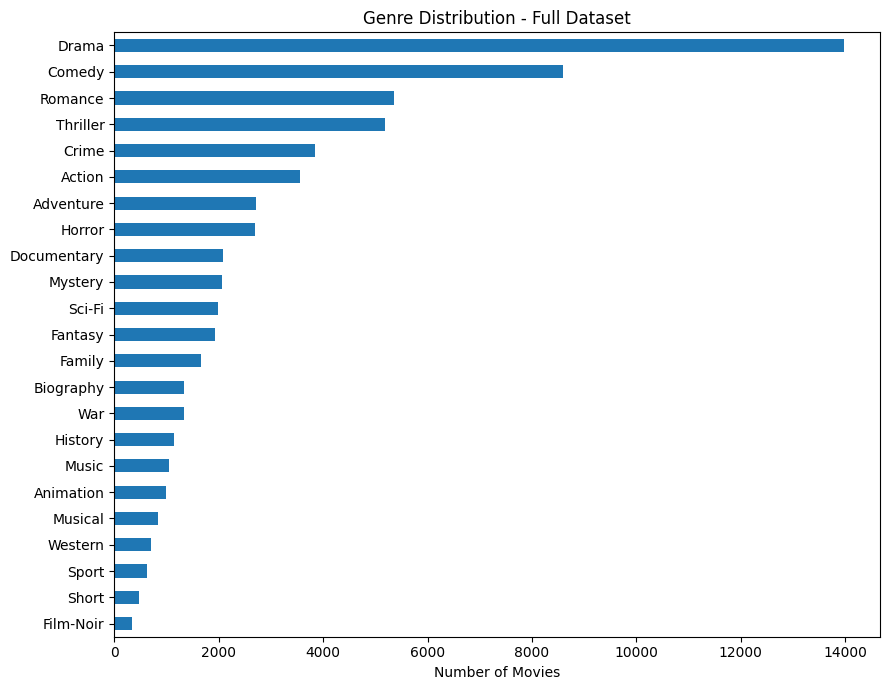

In [6]:
# genre distribution in entire data set
print("============= Genere distibution in entire dataset =======================")
all_labels = mlb.transform(df["genres"])

genre_counts = pd.Series(
    all_labels.sum(axis=0),
    index=genres
)

genre_counts.sort_values().plot.barh(figsize=(9, 7))

plt.title("Genre Distribution - Full Dataset")
plt.xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(base / "genre_distribution_full.png", dpi=200)
plt.show()


============= Genere distibution in training dataset =======================


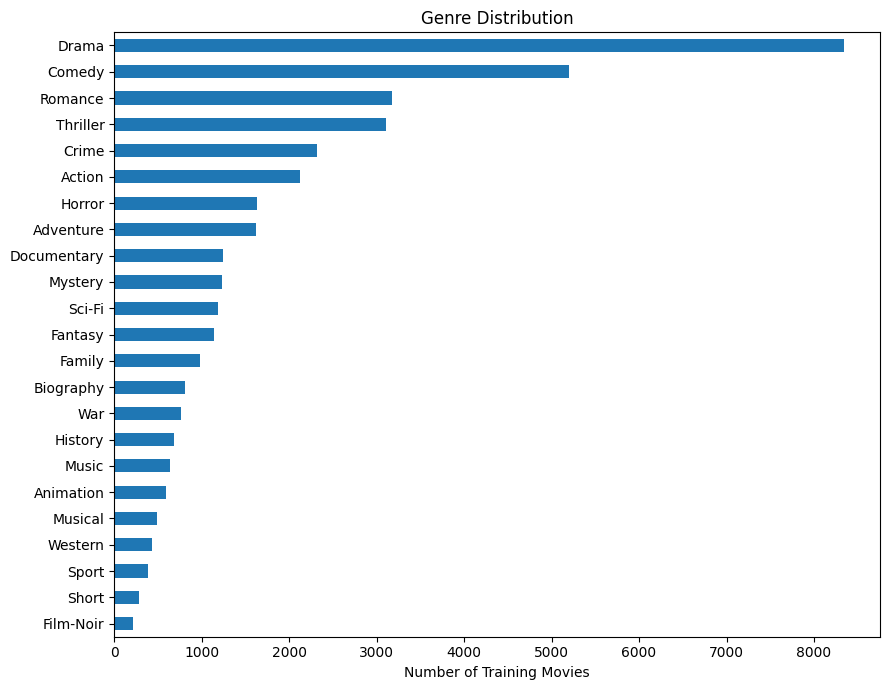

In [7]:
# genre distribution in training data
print("============= Genere distibution in training dataset =======================")
genre_counts = pd.Series(
    y_train.sum(axis=0),
    index=genres
)

genre_counts.sort_values().plot.barh(figsize=(9, 7))

plt.title("Genre Distribution")
plt.xlabel("Number of Training Movies")
plt.tight_layout()
plt.savefig(base / "genre_distribution.png", dpi=200)
plt.show()

# Part 2 — Extract poster and plot features

In [8]:
# Preprocessing steps for EfficientNet
image_weights = EfficientNet_B0_Weights.DEFAULT
transform = image_weights.transforms()


# movie loading class
class MovieDataset(Dataset):

  def __init__(self, frame):
    self.frame = frame.reset_index(drop=True)

  def __len__(self):
    return len(self.frame)

  def __getitem__(self, i):

    row = self.frame.iloc[i]

    # Load poster
    poster = dataset[int(row["id"])]["image"]
    poster = poster.convert("RGB")
    poster = transform(poster)

    #return poster and plot summary
    return poster, row["plot"]


# Pretrained poster feature extractor
image_model= efficientnet_b0(weights=image_weights)

## remove EfficientNet' original classification layer
image_model.classifier = nn.Identity()
image_model.requires_grad_(False)
image_model = image_model.to(device).eval()


# text feature extractor
tokenizer = AutoTokenizer.from_pretrained(
    "google-bert/bert-base-uncased"
)

text_model = AutoModel.from_pretrained(
    "google-bert/bert-base-uncased"
)

# freeze the bert model
text_model.requires_grad_(False)
text_model = text_model.to(device).eval()

print("EfficientNet-B0 and BERT loaded!")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 123MB/s] 


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


EfficientNet-B0 and BERT loaded!


In [9]:
def extract_features(frame, name):
  # File containing extracted features
  file = base / f"{name}_efficientnet_bert256.npz"

  # Reuse saved features if movie IDs match
  if file.exists():

    with np.load(file) as saved:

        if np.array_equal(
            saved["ids"],
            frame["id"].to_numpy()
        ):

          print("Loaded saved features:", name)
          return (saved["image"].copy(),saved["text"].copy())

  # prepare movies into smaller batch
  loader = DataLoader(
      MovieDataset(frame),
      batch_size=8,
      shuffle=False
  )

  image_features = []
  text_features = []

  # Frozen feature extraction
  with torch.no_grad():

    for posters, plots in tqdm(loader, desc=name):

      # get image features
      posters = posters.to(device)

      img=image_model(posters)

      # convert to bert tokens
      tokens = tokenizer(
          list(plots),
          padding=True,
          truncation=True,
          max_length=256,
          return_tensors="pt"
      ).to(device)

      # Extract BERT token representations
      output = text_model(**tokens).last_hidden_state

      # ignoore padding token
      mask = tokens["attention_mask"].unsqueeze(-1)

      #average token features to get one text vector
      txt = (
          (output * mask).sum(dim=1) /
          mask.sum(dim=1).clamp(min=1)
      )

      # save batch of features
      image_features.append(img.cpu().numpy())
      text_features.append(txt.cpu().numpy())


  # combine all batches
  img = np.vstack(image_features).astype("float32")
  txt = np.vstack(text_features).astype("float32")

  # save features
  np.savez_compressed(
      file,
      image=img,
      text=txt,
      ids=frame["id"].to_numpy()
  )

  return img, txt

In [10]:
features = {}
start = time.time()

# extract training, validation and test feature
for name, frame in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:

  features[name] = extract_features(frame, name)


print(
  "Feature extraction/loading time:",
  round(time.time() - start, 2),
  "seconds"
)

print("Image features:", features["train"][0].shape)
print("Text features:", features["train"][1].shape)


# memory free
del image_model, text_model, tokenizer

gc.collect()

if torch.cuda.is_available():
  torch.cuda.empty_cache()

print("Feature extraction completed ....")

train:   0%|          | 0/1947 [00:00<?, ?it/s]

val:   0%|          | 0/325 [00:00<?, ?it/s]

test:   0%|          | 0/974 [00:00<?, ?it/s]

Feature extraction/loading time: 540.75 seconds
Image features: (15570, 1280)
Text features: (15570, 768)
Feature extraction completed ....


In [11]:
# Normalise image and text features
img_scaler = StandardScaler()
txt_scaler = StandardScaler()

# Learn scaling from training data only
img_scaler.fit(features["train"][0])
txt_scaler.fit(features["train"][1])


# labels for each split
labels = {
  "train": y_train,
  "val": y_val,
  "test": y_test
}

loaders = {}

# convert to pytorch
for name in ["train", "val", "test"]:

  img, txt = features[name]

  # normalisation
  img = img_scaler.transform(img).astype("float32")
  txt = txt_scaler.transform(txt).astype("float32")

  data = TensorDataset(
      torch.tensor(img),
      torch.tensor(txt),
      torch.tensor(labels[name], dtype=torch.float32)
  )

  loaders[name] = DataLoader(
      data,
      batch_size=128,
      shuffle=(name == "train")
  )


# Separate unshuffled loader for training evaluation
train_eval_loader = DataLoader(
    loaders["train"].dataset,
    batch_size=128,
    shuffle=False
)


# give importance to rare genres
positive = y_train.sum(axis=0)

class_weights = np.sqrt(
    (len(y_train) - positive + 1) / (positive + 1)
)

class_weights = np.clip(class_weights, 1, 10)

# Loss for multi-label classification
criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=device
    )
)

image_dim = features["train"][0].shape[1]
text_dim = features["train"][1].shape[1]


# Save normalisation setting
np.savez(
    base / "scalers.npz",
    image_mean=img_scaler.mean_,
    image_scale=img_scaler.scale_,
    text_mean=txt_scaler.mean_,
    text_scale=txt_scaler.scale_
)

print("Training data is ready .....")

Training data is ready .....


In [12]:
class GenreModel(nn.Module):
  def __init__(self, mode):
    super().__init__()

    self.mode = mode
    hidden = 128

    # Poster only, plot-only and early fusion
    if mode in ["poster", "plot", "early"]:
      input_sizes = {
          "poster": image_dim,
          "plot": text_dim,
          "early": image_dim + text_dim
      }

      self.head = nn.Sequential(
          nn.Linear(input_sizes[mode], hidden),
          nn.ReLU(),
          nn.Dropout(0.3),
          nn.Linear(hidden, num_genres)
      )

    # GMU and attention fusion
    else:

      self.img_layer = nn.Linear(image_dim, hidden)
      self.txt_layer = nn.Linear(text_dim, hidden)

      if mode == "gmu":
          self.gate = nn.Linear(
              image_dim + text_dim,
              hidden
          )

      if mode == "attention":
          self.score = nn.Linear(hidden, 1)

      self.head = nn.Sequential(
          nn.Dropout(0.3),
          nn.Linear(hidden, num_genres)
      )


  def forward(self, img, txt):

    # 1. poster-only model
    if self.mode == "poster":
      return self.head(img)

    # 2. plot-only model
    if self.mode == "plot":
      return self.head(txt)

    # 3. early fusion: join both features
    if self.mode == "early":

      combined = torch.cat([img, txt], dim=1)
      return self.head(combined)


    # prepare image and text representations
    a = torch.tanh(self.img_layer(img))
    b = torch.tanh(self.txt_layer(txt))

    if self.mode == "gmu":
      gate = torch.sigmoid(
          self.gate(torch.cat([img, txt], dim=1))
      )

      fused = gate * a + (1 - gate) * b

    # 5. Attention: learn importance weights
    else:
      both = torch.stack([a, b], dim=1)

      attention_weights = torch.softmax(
          self.score(both),
          dim=1
      )

      fused = (
          attention_weights * both
      ).sum(dim=1)

    return self.head(fused)


# part A: Two baseline models
baseline_models = ["poster", "plot"]

#part B: Two trainable fusion models
fusion_models = ["early", "gmu"]

#all modle to train
model_names = baseline_models + fusion_models

print("Baseline models:", baseline_models)
print("Fusion models:", fusion_models)

Baseline models: ['poster', 'plot']
Fusion models: ['early', 'gmu']


In [13]:
# Predict probabilities and calculate loss
@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    probabilities = []
    total_loss = 0

    for img, txt, y in loader:

      img = img.to(device)
      txt = txt.to(device)
      y = y.to(device)

      output = model(img, txt)

      total_loss += (
          criterion(output, y).item() * len(y)
      )

      #convertt score to probabilities
      probabilities.append(
          torch.sigmoid(output).cpu().numpy()
      )

    return (np.vstack(probabilities),total_loss / len(loader.dataset))


# Choose the best threshold using validation data
def choose_threshold(y, probs):

  options = np.arange(0.2, 0.81, 0.1)
  return float(max(
      options,
      key=lambda t: f1_score(
          y,
          probs >= t,
          average="micro",
          zero_division=0
      )
  ))


#  calculate evaluation metrics
def get_scores(y, probs, threshold):


  predicted = probs >= threshold

  return {
      "Micro_F1": f1_score(
          y, predicted,
          average="micro",
          zero_division=0
      ),
      "Macro_F1": f1_score(
          y, predicted,
          average="macro",
          zero_division=0
      ),
      "Weighted_F1": f1_score(
          y, predicted,
          average="weighted",
          zero_division=0
      ),
      "Precision": precision_score(
          y, predicted,
          average="micro",
          zero_division=0
      ),
      "Recall": recall_score(
          y, predicted,
          average="micro",
          zero_division=0
      )
  }

print("Evaluation functions was ready !")

Evaluation functions was ready !


In [14]:
# Save results and learning curves
results = []
history = []

# Save predictions for late fusion
val_predictions = {}
test_predictions = {}
thresholds = {}


for name in model_names:
    print("\nTraining model:", name)

    # Create neural network
    model = GenreModel(name).to(device)

    # Adam optimiser
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    # Early stopping variables
    best_loss = float("inf")
    best_weights = None
    patience = 0

    if device == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    # Train for a maximum of 10 epochs
    for epoch in range(10):

      model.train()

      for img, txt, y in loaders["train"]:

        img = img.to(device)
        txt = txt.to(device)
        y = y.to(device)

        # Four main training steps
        optimizer.zero_grad()

        output = model(img, txt)

        loss = criterion(output, y)

        loss.backward()

        optimizer.step()


      # Evaluate training performance
      train_p, train_loss = evaluate(
          model, train_eval_loader
      )

      # Evaluate validation performance
      val_p, val_loss = evaluate(
          model, loaders["val"]
      )

      # Calculate F1 scores
      train_f1 = f1_score(
          y_train,
          train_p >= 0.5,
          average="micro",
          zero_division=0
      )

      val_f1 = f1_score(
          y_val,
          val_p >= 0.5,
          average="micro",
          zero_division=0
      )

      # Save training history
      history.append({
        "Model": name,
        "Epoch": epoch + 1,
        "Train_Loss": train_loss,
        "Val_Loss": val_loss,
        "Train_F1": train_f1,
        "Val_F1": val_f1
      })

      print(
          f"Epoch {epoch + 1}: "
          f"Train F1={train_f1:.3f} | "
          f"Val F1={val_f1:.3f}"
      )

      # Save weights when validation loss improves
      if val_loss < best_loss:

        best_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        patience = 0

      else:
          patience += 1

      # stop if validation loss doean not improve over 4 epochs
      if patience >= 4:
        print("Early stopping")
        break

    if device == "cuda":
      torch.cuda.synchronize()

    training_time = time.perf_counter() - start


    # restore and save best model
    model.load_state_dict(best_weights)

    torch.save(model.state_dict(), base / f"{name}_model.pt")

    # make validation predictions
    vp, _ = evaluate(model, loaders["val"])

    # Measure test time inference
    if device == "cuda":
        torch.cuda.synchronize()

    inference_start = time.perf_counter()
    test_p, _ = evaluate(model, loaders["test"])

    if device == "cuda":
      torch.cuda.synchronize()

    inference_ms = (
      1000 * (time.perf_counter() - inference_start)
      / len(y_test)
    )


    # Choose classification threshold from validation set
    threshold = choose_threshold(y_val, vp)

    # Save predictions
    val_predictions[name] =vp
    test_predictions[name] = test_p
    thresholds[name] = threshold

    # Validation f1
    val_score = get_scores(
        y_val, vp, threshold
    )["Micro_F1"]

    # calculate test results
    results.append({
        "Model": name,
        "Val_F1": val_score,
        **get_scores(y_test, test_p, threshold),
        "Training_Seconds": training_time,
        "Inference_ms": inference_ms,
        "Parameters": sum(p.numel() for p in model.parameters())
    })


    #Save test probabilities
    np.savez_compressed(
      base / f"{name}_predictions.npz",
      probabilities=test_p,
      threshold=threshold
    )

    # remove model from memory
    del model

    if torch.cuda.is_available():
      torch.cuda.empty_cache()

print("\nAll four neural networks trained!")


Training model: poster
Epoch 1: Train F1=0.486 | Val F1=0.458
Epoch 2: Train F1=0.510 | Val F1=0.460
Epoch 3: Train F1=0.534 | Val F1=0.455
Epoch 4: Train F1=0.557 | Val F1=0.456
Epoch 5: Train F1=0.565 | Val F1=0.443
Epoch 6: Train F1=0.593 | Val F1=0.449
Early stopping

Training model: plot
Epoch 1: Train F1=0.639 | Val F1=0.626
Epoch 2: Train F1=0.663 | Val F1=0.640
Epoch 3: Train F1=0.672 | Val F1=0.638
Epoch 4: Train F1=0.680 | Val F1=0.643
Epoch 5: Train F1=0.687 | Val F1=0.644
Epoch 6: Train F1=0.690 | Val F1=0.640
Epoch 7: Train F1=0.698 | Val F1=0.642
Epoch 8: Train F1=0.706 | Val F1=0.643
Early stopping

Training model: early
Epoch 1: Train F1=0.680 | Val F1=0.646
Epoch 2: Train F1=0.709 | Val F1=0.648
Epoch 3: Train F1=0.735 | Val F1=0.655
Epoch 4: Train F1=0.754 | Val F1=0.654
Epoch 5: Train F1=0.768 | Val F1=0.652
Epoch 6: Train F1=0.786 | Val F1=0.651
Early stopping

Training model: gmu
Epoch 1: Train F1=0.669 | Val F1=0.630
Epoch 2: Train F1=0.717 | Val F1=0.642
Epoch 3

In [15]:
# Late fusion combines poster and plot probabilities
best_score = -1

# try different poster and text weight on validation data
for alpha in np.linspace(0, 1, 11):
  combined = (
      alpha * val_predictions["poster"]
      + (1 - alpha) * val_predictions["plot"]
  )

  threshold = choose_threshold(y_val, combined)

  score = get_scores(
      y_val, combined, threshold
  )["Micro_F1"]

  if score > best_score:
    best_score = score
    best_alpha = float(alpha)
    late_threshold = threshold


# Apply selected weights to test predictions
late_probs = (
  best_alpha * test_predictions["poster"]
  + (1 - best_alpha) * test_predictions["plot"]
)

test_predictions["late"] = late_probs
thresholds["late"] = late_threshold


# Late fusion uses two previously trained classifiers
poster_result = results[0]
plot_result = results[1]

results.append({
  "Model": "late",
  "Val_F1": best_score,
  **get_scores(y_test, late_probs, late_threshold),
  "Training_Seconds": (
      poster_result["Training_Seconds"]
      + plot_result["Training_Seconds"]
  ),
  "Inference_ms": (
      poster_result["Inference_ms"]
      + plot_result["Inference_ms"]
  ),
  "Parameters": (
      poster_result["Parameters"]
      + plot_result["Parameters"]
  )
})


# Compare all five approaches
comparison = pd.DataFrame(results)

# Select best model based on validation F1
comparison = comparison.sort_values(
    "Val_F1",
    ascending=False
).reset_index(drop=True)

best_model = comparison.iloc[0]["Model"]

# Save results
comparison.to_csv(base / "model_comparison.csv",index=False)

print("Best model:", best_model)
print("Late fusion poster weight:", best_alpha)
print("Late fusion text weight:", 1 - best_alpha)

display(comparison.round(4))

Best model: late
Late fusion poster weight: 0.4
Late fusion text weight: 0.6


,Model,Val_F1,Micro_F1,Macro_F1,Weighted_F1,Precision,Recall,Training_Seconds,Inference_ms,Parameters
0,late,0.6666,0.6631,0.6031,0.6571,0.6873,0.6405,10.0411,0.0292,268334
1,early,0.6485,0.6497,0.5985,0.6560,0.6169,0.6862,4.2730,0.0153,265239
2,gmu,0.6468,0.6467,0.5915,0.6502,0.6133,0.6840,6.5036,0.0160,527639
3,plot,0.6429,0.6503,0.5962,0.6539,0.6131,0.6922,5.6272,0.0149,101399
4,poster,0.4709,0.4708,0.3299,0.4627,0.4091,0.5543,4.4139,0.0143,166935


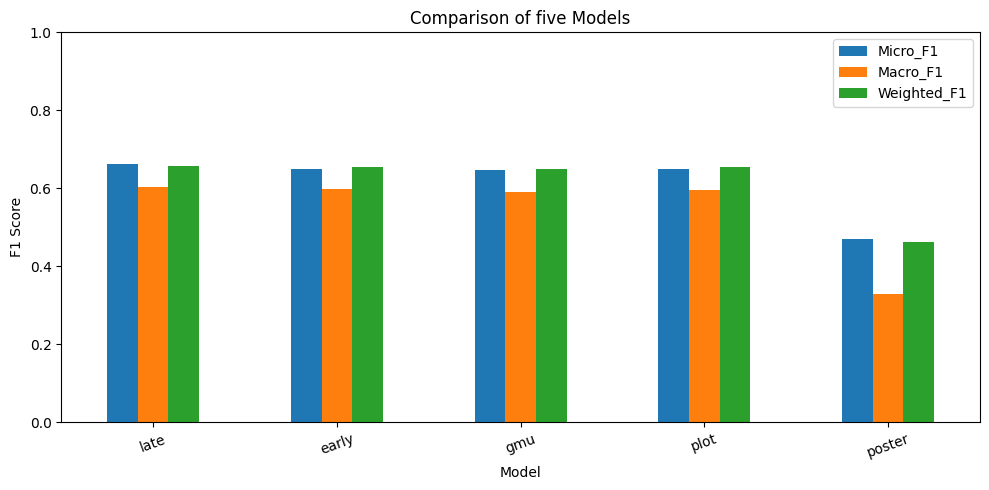

In [16]:
# MODEL COMPARISON
# ==========================================

comparison.set_index("Model")[
    ["Micro_F1", "Macro_F1", "Weighted_F1"]
].plot.bar(figsize=(10, 5))

plt.title("Comparison of five Models")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(base / "model_comparison.png", dpi=200)
plt.show()



# OVERFITTING ANALYSIS
# ==========================================

# Convert training history to DataFrame
history_df = pd.DataFrame(history)

history_df.to_csv(
    base / "training_history.csv",
    index=False
)

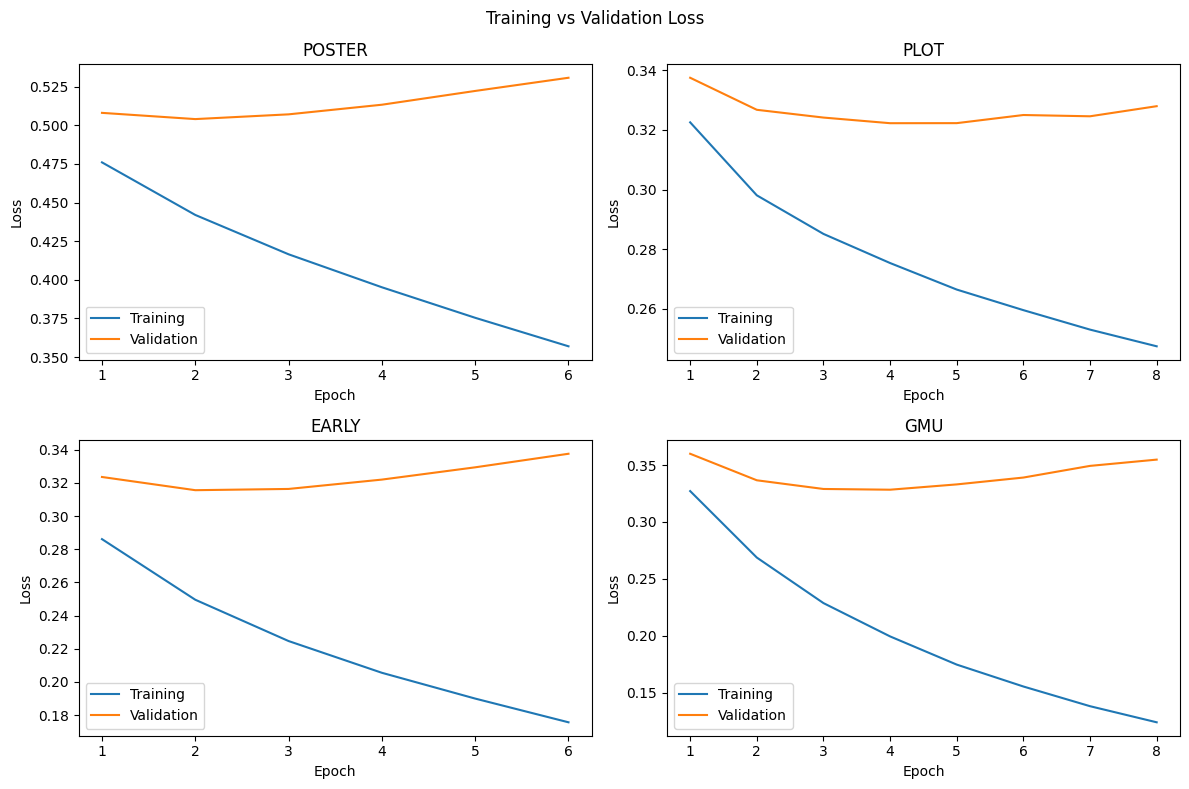

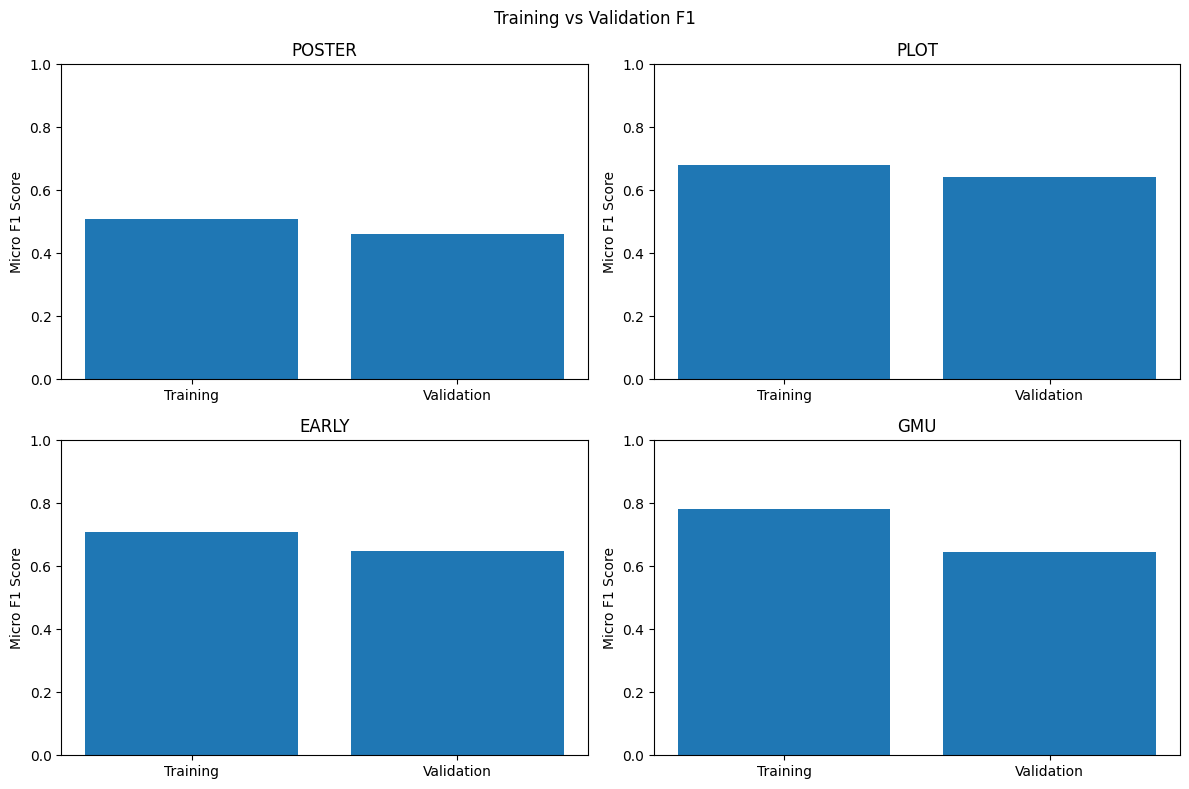

In [17]:
# Compare training and validation loss
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, name in zip(axes.flat, model_names):
  h = history_df[history_df["Model"] == name]

  ax.plot(h["Epoch"], h["Train_Loss"], label="Training")
  ax.plot(h["Epoch"], h["Val_Loss"], label="Validation")

  ax.set_title(name.upper())
  ax.set_xlabel("Epoch")
  ax.set_ylabel("Loss")
  ax.legend()

plt.suptitle("Training vs Validation Loss")
plt.tight_layout()
plt.savefig(base / "overfitting.png", dpi=200)
plt.show()


print("\n=============================================================\n")

print("\n=============================================================\n")


# bar graph
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, name in zip(axes.flat, model_names):
  h = history_df[history_df["Model"] == name]

  last = h.loc[h["Val_Loss"].idxmin()]

  # training and validation f1 scores
  scores = [last["Train_F1"], last["Val_F1"]]

  ax.bar(["Training", "Validation"], scores)

  ax.set_title(name.upper())
  ax.set_ylabel("Micro F1 Score")
  ax.set_ylim(0, 1)

plt.suptitle("Training vs Validation F1")
plt.tight_layout()
plt.savefig(base / "training_validation_f1.png", dpi=200)
plt.show()

Performance on rare genres:


,Genre,Train_Count,Test_Count,poster,plot,early,gmu,late
10,Film-Noir,209,100,0.246,0.301,0.372,0.381,0.327
18,Short,286,144,0.177,0.372,0.370,0.406,0.405
19,Sport,388,193,0.212,0.726,0.676,0.680,0.707
22,Western,433,206,0.309,0.790,0.733,0.712,0.794
14,Musical,487,260,0.253,0.411,0.437,0.407,0.429
2,Animation,594,296,0.529,0.508,0.693,0.674,0.647
13,Music,638,289,0.062,0.629,0.559,0.566,0.583
11,History,679,354,0.128,0.465,0.423,0.421,0.443


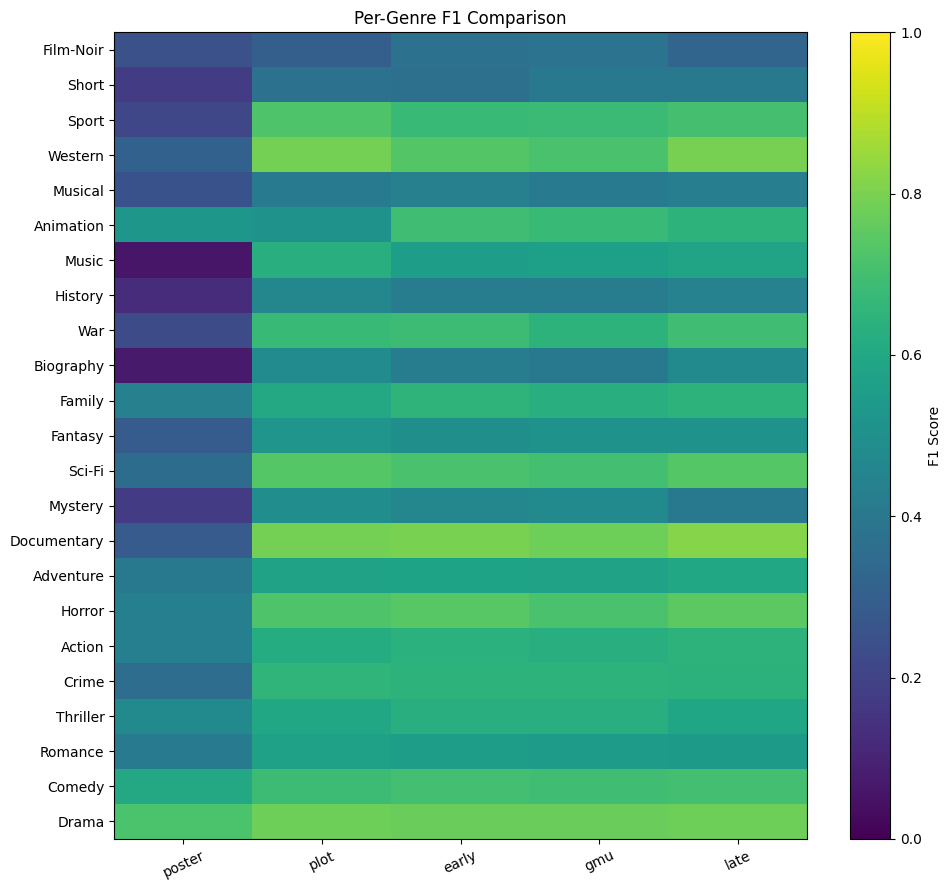

In [18]:
# PER-GENRE F1 SCORES
# ==========================================

per_genre = pd.DataFrame({
  "Genre": genres,
  "Train_Count": y_train.sum(axis=0),
  "Test_Count": y_test.sum(axis=0)
})

# Calculate performance separately for every genre
for name, probs in test_predictions.items():
  per_genre[name] = f1_score(
      y_test,
      probs >= thresholds[name],
      average=None,
      zero_division=0
  )

per_genre = per_genre.sort_values("Train_Count")

per_genre.to_csv(
  base / "per_genre_f1.csv",
  index=False
)

print("Performance on rare genres:")
display(per_genre.head(8).round(3))



# PER-GENRE HEATMAP
# ==========================================
heatmap = per_genre.set_index("Genre")[
    list(test_predictions.keys())
]

plt.figure(figsize=(10, 9))

plt.imshow(
    heatmap,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.colorbar(label="F1 Score")

plt.xticks(

    range(len(heatmap.columns)),
    heatmap.columns,
    rotation=25
)

plt.yticks(
    range(len(heatmap.index)),
    heatmap.index
)

plt.title("Per-Genre F1 Comparison")
plt.tight_layout()

plt.savefig(base / "per_genre_heatmap.png", dpi=200)
plt.show()



In [19]:
# ERROR ANALYSIS
# Predictions from our best validation-selected model
pred = (
    test_predictions[best_model] >= thresholds[best_model]
)

# Number of wrong genre labels per movie
errors = np.sum(pred != y_test, axis=1)

# Select five movies with the most mistakes
worst = np.argsort(errors)[-5:][::-1]

examples = []

for i in worst:
  examples.append({
      "Movie_ID": int(test_df.iloc[i]["id"]),
      "Plot": test_df.iloc[i]["plot"][:160],
      "Actual": ", ".join(genres[y_test[i] == 1]),
      "Predicted": ", ".join(genres[pred[i]]),
      "Errors": int(errors[i])
  })

error_df = pd.DataFrame(examples)

print("Examples of incorrect predictions:")
print("\n=============================================================\n")

print("\n=============================================================\n")

display(error_df)
error_df.to_csv(base / "error_examples.csv",index=False)

Examples of incorrect predictions:






,Movie_ID,Plot,Actual,Predicted,Errors
0,4068,A heavy metal rocker living like an eternal te...,"Biography, Documentary, Drama, Horror, Music","Adventure, Fantasy, Sci-Fi",8
1,5838,A short tale about the demons that slumber dee...,"Action, Animation, Drama, Short, War","Fantasy, Horror",7
2,25707,Gumby is a member of a rock band called The Cl...,"Action, Adventure, Animation, Comedy, Family, ...","Animation, Comedy, Family, Music, Musical",7
3,4476,"""Red"" Jones attempts to prove himself to his s...","Action, Adventure, Comedy, Crime, Romance","Crime, Drama, Film-Noir, Thriller",7
4,1414,Aliens are invading the planet and turning hum...,"Comedy, Horror, Music, Sci-Fi, Thriller","Action, Adventure, Animation, Comedy, Fantasy,...",7


In [20]:
# SAVE EXPERIMENT SETTINGS
settings = {
    "dataset": "pranavmr/MM-IMDb",
    "train_size": len(train_df),
    "val_size": len(val_df),
    "test_size": len(test_df),
    "genres": genres.tolist(),
    "best_model": best_model,
    "thresholds": thresholds,
    "late_poster_weight": best_alpha,
    "split_ids": {
        "train": train_df["id"].tolist(),
        "val": val_df["id"].tolist(),
        "test": test_df["id"].tolist()
    }
}

with open(base / "experiment_settings.json", "w") as f:
    json.dump(settings, f, indent=2)

print("Project experiments completed!")
print("Results saved in:", base)

Project experiments completed!
Results saved in: /content/group17


In [21]:
# PER-GENRE CLASSIFICATION RESULTS
genre_report = pd.DataFrame({
    "Genre": genres,
    "Support": y_test.sum(axis=0),

    "Precision": precision_score(
        y_test, pred,
        average=None,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test, pred,
        average=None,
        zero_division=0
    ),

    "F1": f1_score(
        y_test, pred,
        average=None,
        zero_division=0
    )
})

# Sort by highest F1
genre_report = genre_report.sort_values(
    "F1", ascending=False
)
display(genre_report.round(3))

# Save results
genre_report.to_csv(
    base / "genre_classification_report.csv",
    index=False
)

,Genre,Support,Precision,Recall,F1
6,Documentary,643,0.818,0.816,0.817
22,Western,206,0.859,0.738,0.794
7,Drama,4241,0.747,0.815,0.780
12,Horror,798,0.793,0.711,0.750
17,Sci-Fi,610,0.752,0.721,0.736
19,Sport,193,0.684,0.731,0.707
4,Comedy,2525,0.735,0.669,0.701
21,War,414,0.667,0.725,0.694
2,Animation,296,0.609,0.689,0.647
8,Family,519,0.718,0.588,0.646


In [2]:
# CODE TO DOWNLOAD REQUIRED FILES
import zipfile

# files
report_files = [
    "model_comparison.csv",
    "training_history.csv",
    "per_genre_f1.csv",
    "error_examples.csv",
    "experiment_settings.json",
    "genre_distribution.png",
    "model_comparison.png",
    "overfitting.png",
    "training_validation_f1.png",
    "per_genre_heatmap.png",
    "genre_classification_report.csv"
]

# Create zip file
zip_path = "/content/Group17_Report_Results.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
  for filename in report_files:
    file = base / filename

    if file.exists():
      zipf.write(file, filename)
      print("Added:", filename)
    else:
      print("Not found:", filename)

# download zip
from google.colab import files

files.download(zip_path)

NameError: name 'base' is not defined